# ANLP — Session 4: LLMs for NLP - Part 2

**VLMs for PDF Text Extraction**

This notebook extends on **Part 1** and the Session 4 background slides. If you haven't run Part 1 yet, do that first — this notebook assumes familiarity with the general Ollama chat-completion workflow (serving a model, sending it a request via the OpenAI client), which is covered in Part 1.

**What we'll do in this notebook:**
1. Serve two local vision-language models (VLMs) with Ollama.
2. Convert PDF pages to images, and extract embedded text where it already exists.
3. Use a VLM to perform OCR on scanned pages, and on a full multi-page document.
4. Parse structured tables out of the OCR output.
5. Quantitatively evaluate OCR quality (CER/WER) against an off-the-shelf baseline (`Docling`).


## Setup

As before, we will use [Ollama](https://ollama.com/) to run LLMs / VLMs locally. For a refresher on *why* we need `threading` + `subprocess` to run Ollama's server alongside notebook cells, see Part 1 / the background slides — that mechanism is unchanged here, so we only recap it briefly below.


In [2]:
%%capture
import sys

# ---------------------------------------------------------------------------
# Environment detection
# ---------------------------------------------------------------------------
# We check whether we're running in Google Colab. This lets a single notebook
# work both in Colab (where we install everything into the VM fresh each
# time) and in the course devcontainer (where dependencies are already
# installed from requirements.txt -- see README.md -- so we skip re-installing them).
#
# We'll reuse IN_COLAB again later in this notebook to decide where to store
# downloaded data, so it's defined here rather than inside the `if` block.
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    print("Google Colab environment detected. Installing dependencies...")

    # Ollama itself is not a Python package -- it's a standalone server
    # binary, so we install it via its official shell installer rather than
    # pip. We pin its version via OLLAMA_VERSION.
    !sudo apt update
    !sudo apt install -y pciutils zstd
    !curl -fsSL https://ollama.com/install.sh | OLLAMA_VERSION=0.34.0 sh

    # Python dependencies used in this notebook:
    #   openai        -> lets us talk to Ollama's OpenAI-compatible chat API
    #   pypdfium2     -> renders PDF pages to images / extracts embedded text
    #   jiwer         -> computes CER/WER for OCR evaluation
    #   docling       -> off-the-shelf document parser we use as a comparison baseline
    #   gdown         -> downloads the course data folder from Google Drive
    #   tqdm, pillow, pandas, beautifulsoup4, html5lib -> progress bars, images, tables, HTML parsing
    %pip install openai==3.3.0 pypdfium2==5.15.2 jiwer==4.0.0 docling==2.150.0 gdown==6.5.1 tqdm==4.70.1 pillow==13.0.0 pandas==3.0.3 beautifulsoup4==4.15.0 html5lib==1.1

Ollama runs as a background *server* process, separate from the sequential, cell-by-cell execution of a notebook. Part 1 and the background slides cover *why* this mismatch requires a `threading` + `subprocess` workaround in detail — here's the short recap:

- `subprocess.Popen(["ollama", "serve"])` starts the Ollama server as its own OS process, without blocking Python.
- We run that inside a `thread` so the rest of the notebook can keep executing while the server runs in the background.
- `time.sleep(5)` gives the server a moment to finish starting up before the next cells try to use it.


In [3]:
import threading
import subprocess
import time

def run_ollama_serve():
    """Start the Ollama server as a background OS process.

    subprocess.Popen (unlike subprocess.run) does NOT block: it launches
    'ollama serve' and immediately returns control to Python, while the
    server keeps running in the background.
    """
    subprocess.Popen(["ollama", "serve"])

if IN_COLAB:
    # We run run_ollama_serve() in its own thread so that starting the server
    # doesn't block the rest of this notebook.
    # daemon=True means this background thread will be cleaned up automatically
    # when the notebook's Python process shuts down, instead of lingering.
    thread = threading.Thread(target=run_ollama_serve, daemon=True)
    thread.start()

    # Give the Ollama server a few seconds to finish starting up before the next
    # cells (pulling models, sending requests) try to talk to it.
    time.sleep(5)


To download a model, use `ollama pull`. For the full list of models available, check https://ollama.com/library

We'll pull **two** different vision-language models, so that we can compare a general-purpose VLM against a model specialised for OCR:

- **`gemma4:e2b`** — a general-purpose, edge-sized multimodal model. It can read images, but text extraction isn't its specialty.
- **`maternion/LightOnOCR-2`** — a VLM fine-tuned specifically for OCR, including structured output for tables (see "Handling tables" below).

Both downloads may take a few minutes the first time, since model weights are several GB.


In [4]:
%%capture

# MODEL = 'gemma4:e2b'  # general-purpose VLM baseline
# !ollama pull {MODEL}

MODEL = 'maternion/LightOnOCR-2'  # OCR-specialised VLM
!ollama pull {MODEL}


In [5]:
# Query the OpenAI-compatible endpoint directly, to confirm the server is up
# and see which models it currently knows about.
!curl -Ss http://localhost:11434/v1/models


{"object":"list","data":[{"id":"maternion/LightOnOCR-2:latest","object":"model","created":1783677479,"owned_by":"maternion"}]}


## Pulling in the data

For this demo, we'll work with a multi-page PDF and some scanned documents as PNG files. The data is available in the Google Drive folder for this session.

**A note on file paths:** this notebook is designed to run either in Google Colab or locally. We define a single `DATA_DIR` variable below, based on the environment, and use it throughout this notebook. If you're running locally, the data will be downloaded into a `session_4_data/` folder created next to this notebook. If running in Google Colab, we'll use `/content/session_4_data`.


In [6]:
from pathlib import Path

# Every file path later in this notebook is built from DATA_DIR, so this is
# the *only* place you'd need to change something if your data lived
# somewhere else.
DATA_DIR = Path("/content/session_4_data") if IN_COLAB else Path("session_4_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Using DATA_DIR = {DATA_DIR.resolve()}")


Using DATA_DIR = /content/session_4_data


In [7]:
import gdown

# Fetch the prepared data folder from Google Drive directly into DATA_DIR, so
# the rest of the notebook can rely on one consistent location for all input
# files, whether we're in Colab or running locally.
url = "https://drive.google.com/drive/folders/1HNSjcMQkNUJxHbdAqUWIPrS0E0DCSGcV"
gdown.download_folder(url=url, output=str(DATA_DIR))


Retrieving folder contents


Processing file 1BHRMEFzHqFlq7G-O3rfDch_P1v6YbEoJ Franz_Etymolog_Woerterbuch_0033.png
Processing file 1lod6YkGAKI03QISmUybdTyDoQDivWT4R UZH_Jahresbericht_2023-sample-multi.pdf
Processing file 1TKQZR4Cwyz1Qr9YFgj6-cbUsc_SW4yuQ UZH_Jahresbericht_2023-sample-single.md
Processing file 1j6p6bcsAiiQrn51CZrkJCcYzf6ZV2wxh UZH_Jahresbericht_2023-sample-single.pdf


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1BHRMEFzHqFlq7G-O3rfDch_P1v6YbEoJ
To: /content/session_4_data/Franz_Etymolog_Woerterbuch_0033.png
100%|██████████| 3.42M/3.42M [00:00<00:00, 62.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1lod6YkGAKI03QISmUybdTyDoQDivWT4R
To: /content/session_4_data/UZH_Jahresbericht_2023-sample-multi.pdf
100%|██████████| 202k/202k [00:00<00:00, 61.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1TKQZR4Cwyz1Qr9YFgj6-cbUsc_SW4yuQ
To: /content/session_4_data/UZH_Jahresbericht_2023-sample-single.md
100%|██████████| 4.99k/4.99k [00:00<00:00, 16.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1j6p6bcsAiiQrn51CZrkJCcYzf6ZV2wxh
To: /content/session_4_data/UZH_Jahresbericht_2023-sample-single.pdf
100%|██████████| 49.3k/49.3k [00:00<00:00, 73.7MB/s]
Download completed


['/content/session_4_data/Franz_Etymolog_Woerterbuch_0033.png',
 '/content/session_4_data/UZH_Jahresbericht_2023-sample-multi.pdf',
 '/content/session_4_data/UZH_Jahresbericht_2023-sample-single.md',
 '/content/session_4_data/UZH_Jahresbericht_2023-sample-single.pdf']

In [8]:
# Sanity check: make sure the expected files downloaded correctly before
# continuing. Catching a missing/misnamed file here -- with a clear message
# -- is much easier to debug than a confusing FileNotFoundError several
# cells further into the notebook.
expected_files = [
    DATA_DIR / "UZH_Jahresbericht_2023-sample-single.pdf",
    DATA_DIR / "UZH_Jahresbericht_2023-sample-single.md",
    DATA_DIR / "UZH_Jahresbericht_2023-sample-multi.pdf",
    DATA_DIR / "Franz_Etymolog_Woerterbuch_0033.png",
]

for file in expected_files:
    if not file.exists():
        raise Exception(f"File not found: {file}")
print(f"All {len(expected_files)} files exist!")


All 4 files exist!


## OCR with VLMs - Processing PDFs

VLMs can handle text and images — not PDFs directly.
Therefore, we need to convert our input PDF into a series of page images before we can send it to a VLM.
For this, we'll use [`pypdfium2`](https://pypi.org/project/pypdfium2/), a Python library for PDF creation, inspection, manipulation and rendering, and [`pillow`](https://pillow.readthedocs.io/en/stable/index.html), an imaging library.


In [9]:
import pypdfium2 as pdfium
from tqdm import tqdm

pdf_path = DATA_DIR / "UZH_Jahresbericht_2023-sample-single.pdf"
pdf = pdfium.PdfDocument(str(pdf_path))
n_pages = len(pdf)

print(f"PDF has {n_pages} pages.")


PDF has 1 pages.


Note, `pypdfium2` also supports text extraction for PDFs with embedded font and character data layers (not scans or images, which would require OCR).

In [9]:
# `page` and `textpage` are reused later in this notebook (e.g. to render an
# image in the next section), so we keep these exact variable names here.
page = pdf[0]

# get_textpage() gives us access to the PDF's embedded text layer (character
# positions plus font/encoding info) -- this only exists for "digital" PDFs,
# not for scanned pages, which is why we turn to OCR further below.
textpage = page.get_textpage()

# Extract all text on the page, in reading order.
text_all = textpage.get_text_range()
print(f"{text_all[:500]}...")


Interview
Universität Zürich | Jahresbericht 2023 31
Profil Entdecken Governance Statistik Finanzen Impressum
Anhang zur Jahresrechnung
Grundsätze der Rechnungslegung
Grundlagen
Die Jahresrechnung der Universität Zürich (UZH) berücksichtigt das auf den 
1.1.2010 in Kraft getretene Finanzreglement der UZH und basiert auf dem 
Gesetz über Controlling und Rechnungslegung (CRG) vom 9.1.2006 und sei￾nen Ausführungserlassen. Dabei basieren die wichtigsten Grundsätze der 
Rechnungslegung – mit...


In [10]:
# pypdfium2 also lets us inspect individual characters:
# their text content and exact bounding box.
# This kind of fine-grained, structured information is only available
# because this PDF has an embedded text layer.
num_chars = textpage.count_chars()

for i in range(10):
    # loose=True captures a slightly larger/looser bounding box
    left, bottom, right, top = textpage.get_charbox(i, loose=True)
    char = textpage.get_text_range(i, 1)
    print(f"Char: '{char}' | BBox: (left={left}, bottom={bottom}, right={right}, top={top})")


Char: 'I' | BBox: (left=20.55120086669922, bottom=566.7962036132812, right=22.88395118713379, top=576.5379028320312)
Char: 'n' | BBox: (left=23.000200271606445, bottom=566.7962036132812, right=27.43320083618164, top=576.5379028320312)
Char: 't' | BBox: (left=27.526201248168945, bottom=566.7962036132812, right=30.49445152282715, top=576.5379028320312)
Char: 'e' | BBox: (left=30.579700469970703, bottom=566.7962036132812, right=34.594200134277344, top=576.5379028320312)
Char: 'r' | BBox: (left=34.7259521484375, bottom=566.7962036132812, right=37.818199157714844, top=576.5379028320312)
Char: 'v' | BBox: (left=38.159202575683594, bottom=566.7962036132812, right=42.21245574951172, top=576.5379028320312)
Char: 'i' | BBox: (left=42.320953369140625, bottom=566.7962036132812, right=44.45995330810547, top=576.5379028320312)
Char: 'e' | BBox: (left=44.583953857421875, bottom=566.7962036132812, right=48.598453521728516, top=576.5379028320312)
Char: 'w' | BBox: (left=48.65270233154297, bottom=566.79

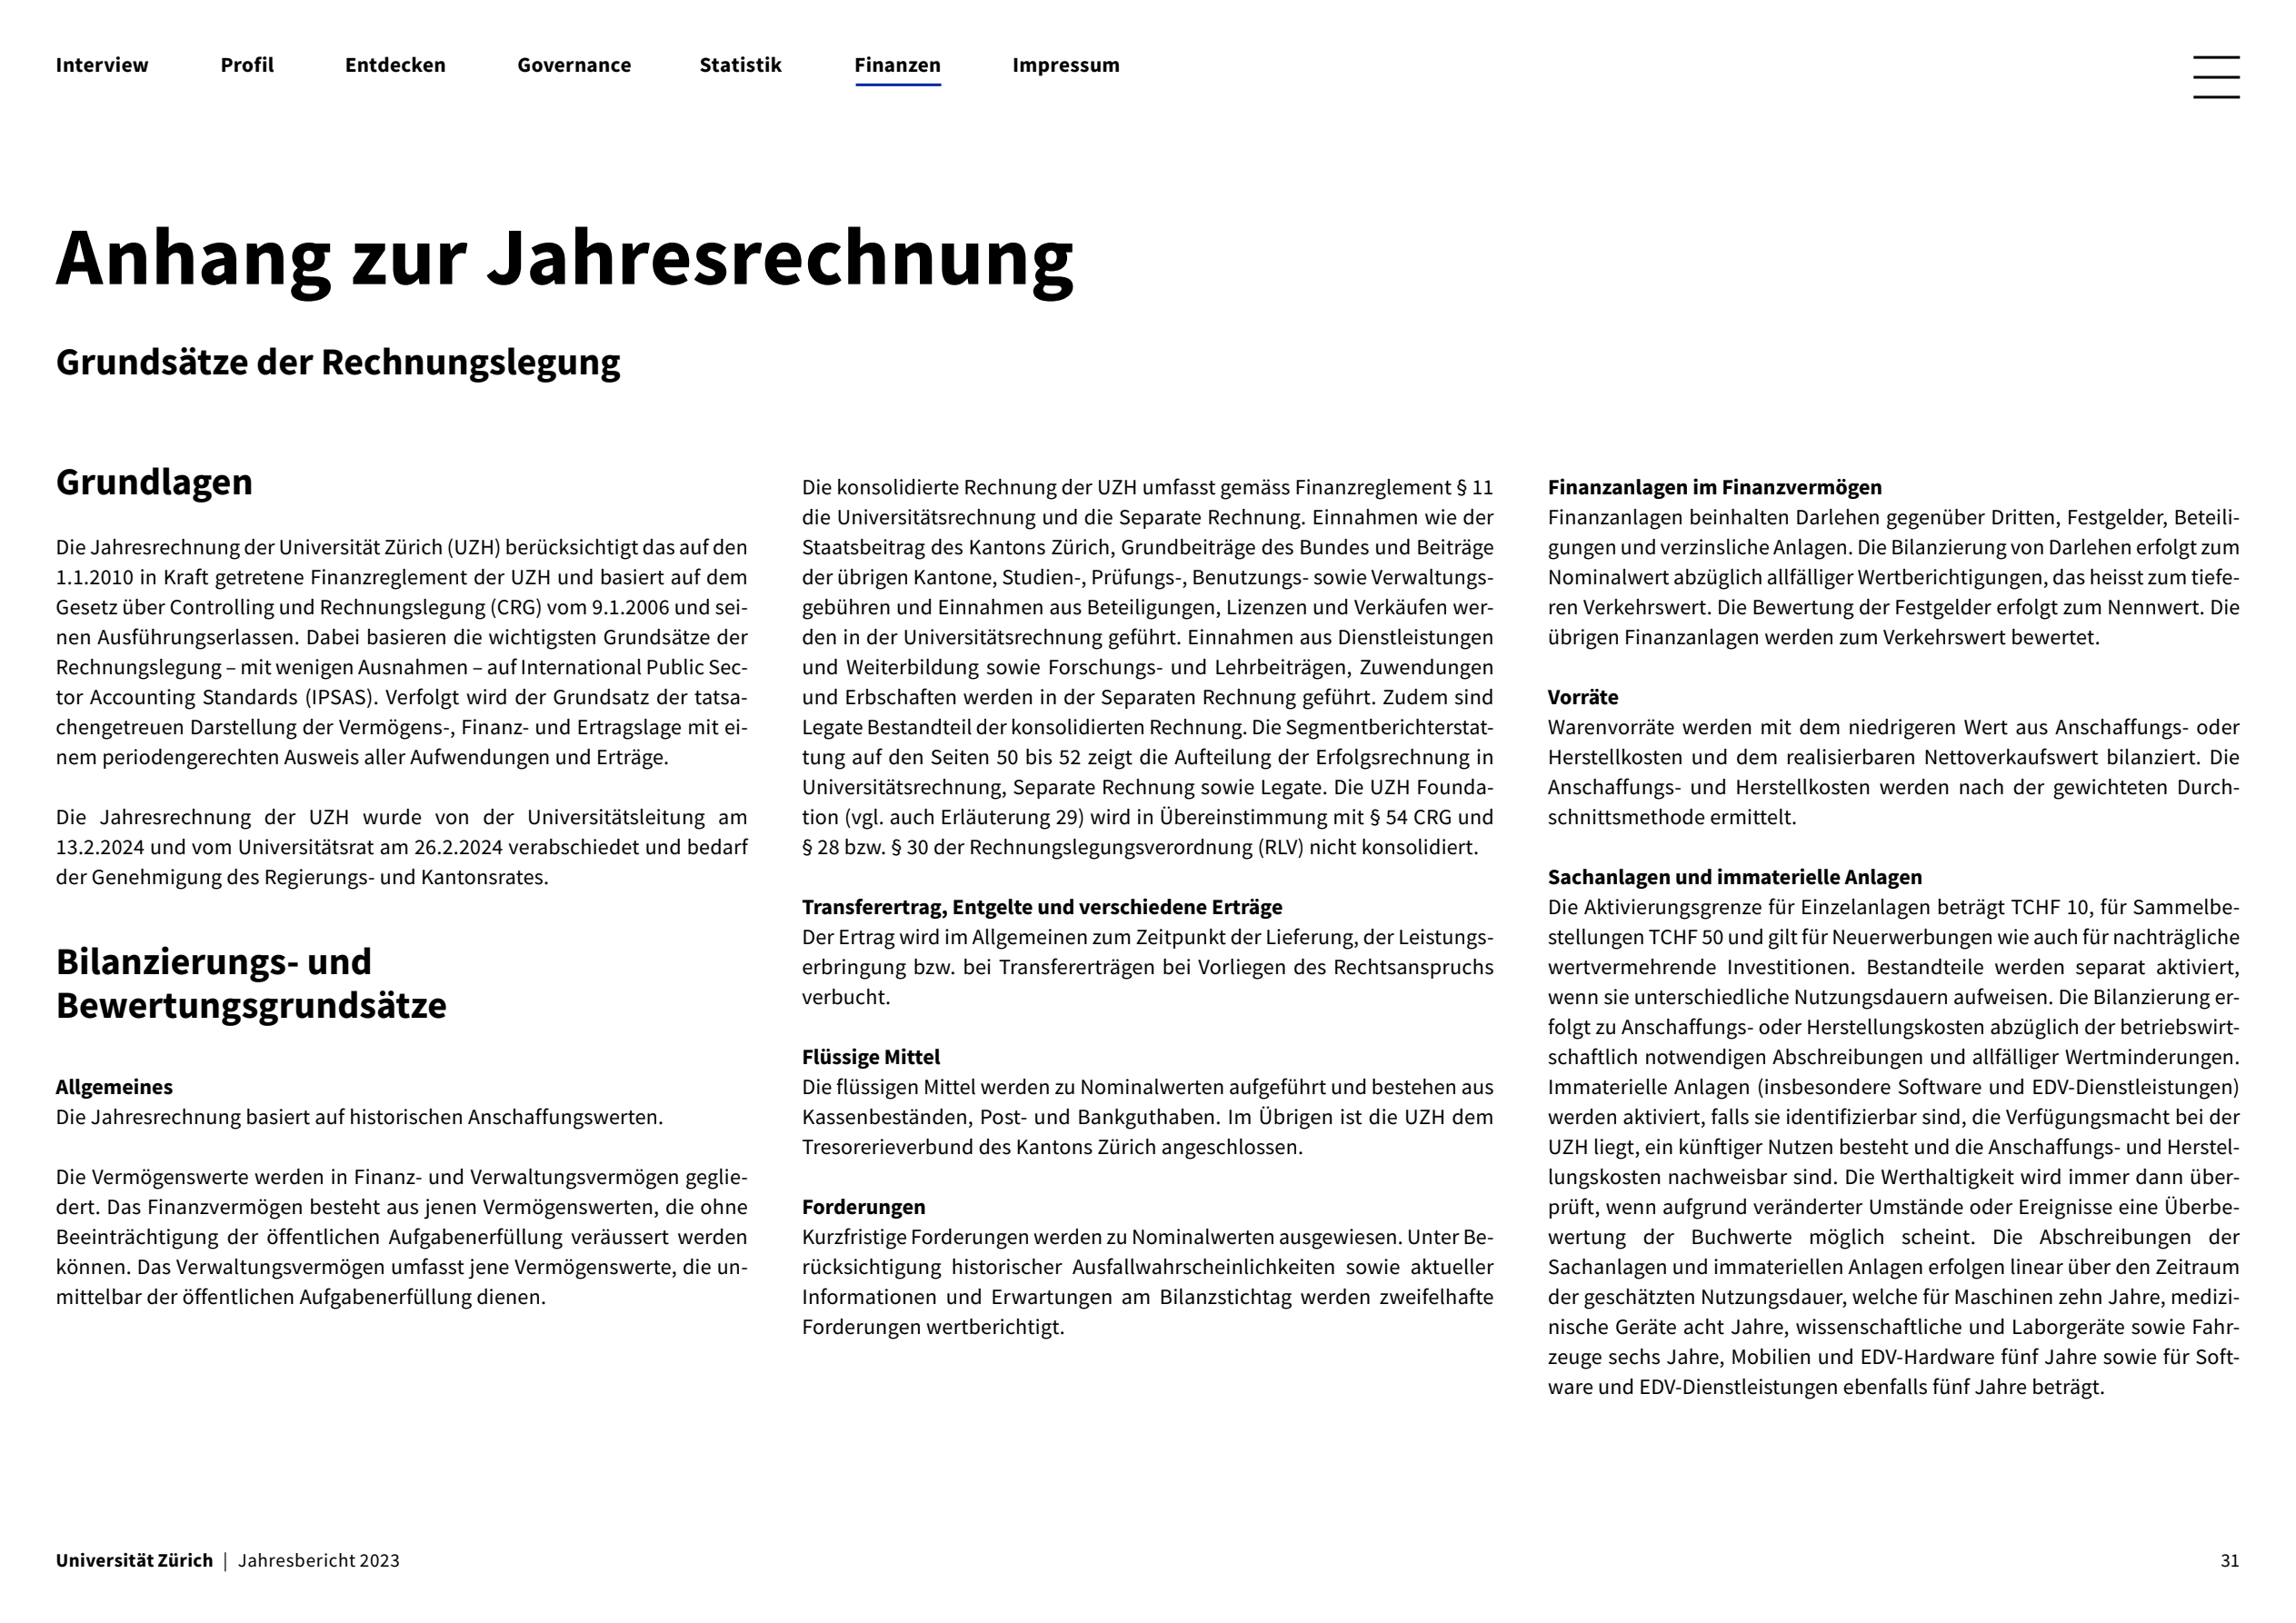

In [11]:
from PIL import Image

def convert_pdf_page_to_image(pdf_page: pdfium.PdfPage, scale: float = 2.0) -> Image.Image:
    """
    Converts a single PDF page to a PIL Image object.

    Args:
        pdf_page: The pypdfium2 PdfPage object to convert.
        scale: The scaling factor for rendering. A higher value results in a
            higher resolution image -- useful for OCR, since small or
            blurry text is harder for a VLM to read correctly.

    Returns:
        A PIL Image object representing the rendered PDF page.
    """
    # Render the PDF page to a bitmap, then convert it to a PIL Image so we
    # can save it as a standard image file (e.g. PNG) for the VLM to consume.
    pil_image = pdf_page.render(scale=scale).to_pil()
    return pil_image

# We render at a higher scale (3.0) than the function default (2.0), since
# VLMs generally perform better OCR on higher-resolution input images.
page_image = convert_pdf_page_to_image(page, scale=3.0)

# Save the rendered page image to disk, so we can pass its path to ocr_page().
page_image_path = "/tmp/image.png"
page_image.save(page_image_path)

page_image


In [12]:
### without GPU, this block needs about 2 minutes
from typing import Optional
import base64
from openai import OpenAI

def encode_image(image_path: str) -> str:
    """
    Encodes an image file as a base64 string.

    VLM APIs that accept images inline (rather than via a public URL) expect
    the image bytes to be base64-encoded and embedded directly in the
    request.

    Args:
        image_path (str): The path to the image file.

    Returns:
        str: The base64-encoded string.
    """
    with open(image_path, "rb") as image_file:
        encoded_string = base64.b64encode(image_file.read()).decode("utf-8")
    return encoded_string


def ocr_page(image_path: str, model_name: str, prompt: Optional[str] = None) -> str:
    """
    Performs OCR on an image using an Ollama-served VLM (through OpenAI-compatible API)

    Args:
        image_path (str): The path to the image file.
        model_name (str): The name of the VLM to use.
        prompt (str): The text instruction sent alongside the image.
            Defaults to a simple "extract text verbatim" instruction.

    Returns:
        str: The extracted text from the image.
    """
    # Ollama exposes an OpenAI-compatible API, so we reuse the `openai`
    # client library by pointing it at our local server instead of OpenAI's.
    # The api_key is required by the client library but ignored by Ollama.
    client = OpenAI(
        base_url="http://localhost:11434/v1/",
        api_key="ollama",
    )

    encoded_image = encode_image(image_path)

    if prompt:
        # A single multimodal chat message: one user turn containing both a text
        # instruction and an image, the latter encoded as a base64 data URL.
        content = [
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{encoded_image}"}},
        ]
    else:
        # No instruction here, just the image
        content = [
            {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{encoded_image}"}},
        ]

    chat_completion = client.chat.completions.create(
        messages=[
            {
                "role": "user",
                "content": content,
            },
        ],
        model=model_name,
        max_tokens=4096,
        # temperature=0.0 and top_p=1.0 make generation as deterministic as
        # possible. For OCR we want the *most likely* reading of the page,
        # not a creative or varied one.
        temperature=0.0,
        top_p=1.0,
    )

    return chat_completion.choices[0].message.content

page_text = ocr_page(
    image_path=page_image_path,
    model_name="gemma4:e2b",
    prompt="Look at the attached image and extract the text content to markdown format."
)

with open(DATA_DIR / "UZH_Jahresbericht_2023-sample-single--gemma4:e2b.md", "w") as f:
    f.write(page_text)
    print("Wrote output to file.")

print(page_text[:800])

Wrote output to file.
Based on the image provided, here is the extracted text in Markdown format:

***

### Anhang zur Jahresrechnung

#### Grundsätze der Rechnungslegung

Die Jahresrechnung der Universität / UZH umfasst gemäß Finanzreglement § 11 die Universitätsrechnung und die separate Rechnung. Einrahmen wie der Stabsatz des Kantons Zürich, Grundbuchs des Bundes und Heilräge der Universität, sowie die Rechnungslegungsvorschriften, die sich auf die Rechnungslegung beziehen, sind in der Universitätsrechnung gefasst. Ein Rahmen für die Rechnungslegung ist die Jahresrechnung selbst. Die Jahresrechnung wird mit den Jahresergebnissen und den Erträgen zusammengefasst, die sich auf die Rechnungslegung beziehen. Die Jahresrechnung enthält die Ergebnisse der laufenden und periodischen Aktivitäten sowie die Erträge un


In [13]:
# Now let's run the exact same image through the OCR-specialised model, to
# compare its output against the general-purpose VLM above.
page_text = ocr_page(
    image_path=page_image_path,
    model_name="maternion/LightOnOCR-2",
)

with open(DATA_DIR / "UZH_Jahresbericht_2023-sample-single--LightOnOCR-2.md", "w") as f:
    f.write(page_text)
    print("Wrote output to file.")

print(page_text[:800])


Wrote output to file.
Interview Profil Entdecken Governance Statistik **Finanzen** Impressum

# Anhang zur Jahresrechnung

## Grundsätze der Rechnungslegung

### Grundlagen

Die Jahresrechnung der Universität Zürich (UZH) berücksichtigt das auf den 1.1.2010 in Kraft getretene Finanzreglement der UZH und basiert auf dem Gesetz über Controlling und Rechnungslegung (CRG) vom 9.1.2006 und seinen Ausführungserlassen. Dabei basieren die wichtigsten Grundsätze der Rechnungslegung – mit wenigen Ausnahmen – auf International Public Sector Accounting Standards (IPSAS). Verfolgt wird der Grundsatz der tatsachengetreuen Darstellung der Vermögens-, Finanz- und Ertragslage mit einem periodengerechten Ausweis aller Aufwendungen und Erträge.

Die Jahresrechnung der UZH wurde von der Universitätsleitung am 13.2.2024 und vom Uni


#### Comprehension Questions

1. What differences do you notice between the two models' outputs? Are there differences in **accuracy** (wrong characters/words), **formatting** (layout, whitespace, punctuation), or both?

2. Why do we specify a prompt for text extraction with `gemma4` but not for the `LightOn` model?

2. Given what you know about `gemma4:e2b` (general-purpose) versus `LightOnOCR-2` (OCR-specialised), which would you trust more for a scanned form full of numbers? What about a photo of a handwritten note?

3. Looking at `ocr_page()`: what would you expect to happen to the output if you increased `temperature` from `0.0` to, say, `0.9`? Would that be desirable for an OCR task and why?


**👉 Your turn** — write your own VLM prompt

`ocr_page()` accepts an optional `prompt` argument (it defaults to `None`). Try writing your own instruction to guide a general-purpose VLM towards a specific task. For example, ask the model to:

- summarise the page instead of transcribing it verbatim,
- transcribe only a specific part of the page (e.g. a specific column, figure, numbers, etc.),
- return the transcription formatted as a bulleted list,

and see how the output changes.

In [14]:
# TODO: write your own prompt below, then run this cell.
my_prompt = ""

# uncomment the following lines to run your own prompt through the OCR-specialised model
# my_ocr_output = ocr_page(
#     image_path=page_image_path, # reuses the page image rendered above
#     model_name="gemma4:e2b",
#     prompt=my_prompt,
# )

# print(f"Prompt: {my_prompt}\n")
# print("-" * 40)
# print(my_ocr_output)


In [15]:
def process_multipage_pdf(pdf_path: str, model_name: str) -> str:
    """
    Processes a multi-page PDF document using an Ollama-compatible VLM.

    Args:
        pdf_path (str): The path to the PDF file.
        model_name (str): The name of the VLM to use.

    Returns:
        str: The extracted text from the PDF.
    """
    # Accept either a str or a Path -- we use Path-only methods (.name)
    # further down, so normalise the input here rather than assuming the
    # caller passed the "right" type.
    pdf_path = Path(pdf_path)

    page_texts = []

    # Load the PDF and get the number of pages.
    pdf = pdfium.PdfDocument(str(pdf_path))
    n_pages = len(pdf)

    # For each page: render it to an image, run OCR, and collect the text.
    # tqdm gives us a progress bar, since OCR-ing many pages can take a while.
    for page_idx in tqdm(range(n_pages), desc="  pages", leave=False, unit="pg"):
        page_num = page_idx + 1

        # A custom marker lets us later locate page boundaries in the
        # combined output text (e.g. for debugging, or for splitting the
        # document back into individual pages).
        marker = f"<!-- page {page_num} -->"

        # A local variable, distinct from the `page` object used earlier in
        # the notebook -- this loop has its own page for each iteration.
        current_page = pdf[page_idx]

        # Render + save the page image, then send it to the VLM.
        page_image = convert_pdf_page_to_image(current_page, scale=3.0)
        page_image_path = pdf_path.parent / f"{pdf_path.stem}--{page_num}.png"
        page_image.save(page_image_path)

        try:
            text = ocr_page(
                image_path=page_image_path,
                model_name=model_name,
            )
            page_texts.append(f"{marker}\n\n{text.strip()}")
        except Exception as e:
            # We catch (rather than let propagate) so that one bad page
            # doesn't crash the whole multi-page run -- we'd rather get
            # 9/10 pages back with one clearly-marked failure than lose the
            # entire document.
            print(f"[!] {pdf_path.name} p{page_num}: OCR failed — {e}")
            page_texts.append(f"{marker}\n\n<!-- OCR FAILED: {e} -->")

    text = "\n\n".join(page_texts)

    return text


doc_text = process_multipage_pdf(
    pdf_path=DATA_DIR / "UZH_Jahresbericht_2023-sample-multi.pdf",
    model_name="maternion/LightOnOCR-2",
)

# Full OCR'd document text, with page-boundary markers inserted by
# process_multipage_doc().
print(doc_text)

<!-- page 1 -->

Interview Profil Entdecken Governance **Statistik** Finanzen Impressum

---

## Statistik

# UZH in Zahlen

### Studierende

#### Total nach Studienstufe

- 14 382 Bachelor
- 7 557 Master
- 576 Lehrdiplom
- 5 443 Doktorat

#### Abschlüsse nach Studienstufe

- 2 790 Bachelor
- 2 844 Master
- 180 Lehrdiplom
- 879 Doktorat

#### Total nach Fakultät

- 288 Theologische Fakultät *
- 3 850 Rechtswissenschaftliche Fakultät
- 4 239 Wirtschaftswissenschaftliche Fakultät
- 3 951 Medizinische Fakultät
- 769 Vetsuisse-Fakultät
- 9 824 Philosophische Fakultät
- 5 037 Mathematisch-naturwiss. Fakultät

*Die Theologische Fakultät heisst seit dem 1.1.2024 Theologische und Religionswissenschaftliche Fakultät.

---

### Mitarbeitende

#### Total nach Personalgruppe

- 738 Professuren
- 5 846 Mittelbau
- 3 523 Administratives und technisches Personal

#### Total nach Organisation

- 109 Theologische Fakultät
- 519 Rechtswissenschaftliche Fakultät
- 675 Wirtschaftswissenschaftliche Fakultä

#### Comprehension Questions

1. Why does `process_multipage_doc()` call the VLM **once per page**, instead of sending every page image in a single prompt? Think about context-window limits, memory/compute cost, and what happens if just *one* page is hard to read.

2. Look at the `try`/`except` block inside the loop. What would change about the function's behaviour if that error handling were removed? Would you rather get a 9-page document with page 9 marked `OCR FAILED`, or no document at all if page 9 fails?

3. What role does the `marker` (`<!-- page N -->`) play in the returned text? Where else in this notebook (or in a downstream application) might that be useful?


## Handling tables

Depending on the VLM used, we can extract tables by creating a custom parser.

The OCR-specific VLM `LightOnOCR-2` has been trained to encode tables using HTML markup (`<table>`, `<tr>`, `<td>`, ...) rather than plain Markdown, since HTML can represent things like merged cells and nested headers that a Markdown table cannot.

To extract tabular content from the text, we'll parse the resulting text with `BeautifulSoup` and iterate through any `<table>` tags we find, converting each one into a `pandas.DataFrame`.


In [16]:
import pandas as pd
from io import StringIO
from bs4 import BeautifulSoup


def extract_tables_from_markdown(text: str) -> list[pd.DataFrame]:
    """
    Extracts HTML tables from a markdown/text string and returns them as a
    list of pandas DataFrames.

    This only works because LightOnOCR-2 encodes tables as HTML <table>
    markup within its output -- a different VLM might use plain Markdown
    pipe-tables instead, which would need a different parsing approach.
    """
    # Parse the text as HTML. BeautifulSoup simply ignores any surrounding
    # plain text/markdown that isn't itself valid HTML.
    soup = BeautifulSoup(text, "html.parser")

    # Find every <table> element in the document, regardless of which page
    # it came from.
    table_tags = soup.find_all("table")

    tables = []
    for table in table_tags:
        try:
            # pandas can parse a single HTML table string directly into a
            # DataFrame. We use StringIO to avoid a pandas FutureWarning
            # about passing raw strings to read_html.
            df_list = pd.read_html(StringIO(str(table)), flavor="bs4")
            if df_list:
                tables.append(df_list[0])
        except ValueError:
            # pandas raises ValueError if it can't find/parse a table in the
            # given HTML snippet -- we simply skip these rather than crash.
            continue

    return tables


# Test it on the multi-page OCR output produced above.
tables = extract_tables_from_markdown(doc_text)
print(f"Extracted {len(tables)} tables.")
for i, df in enumerate(tables):
    print(f"\n--- Table {i + 1} ---")
    display(df)


Extracted 1 tables.

--- Table 1 ---


Unnamed: 0_level_0   Total         Bachelor          \
                       Unnamed: 0_level_1    2022    2023     2022    2023   
0                       Total Studierende  27 895  27 958   14 353  14 382   
1                       Frauenanteil in %    58.9    59.3     59.3    59.7   
2                       Männeranteil in %    41.1    40.7     40.7    40.3   
3           Anteil Ausländer/-innen in %1    18.7    19.1      5.8     5.7   
4                         nach Fakultäten  27 895  27 958   14 353  14 382   
5                   Theologische Fakultät     299     288      122     116   
6        Rechtswissenschaftliche Fakultät   3 961   3 850    2 515   2 371   
7   Wirtschaftswissenschaftliche Fakultät   4 120   4 239    2 244   2 352   
8                   Medizinische Fakultät   4 048   3 951    1 355   1 408   
9                      Vetsuisse-Fakultät     770     769      306     297   
10                Philosophische Fakultät   9 829   9 824    5 512   5 455   
11       Mathematisch-naturwiss. Fakultät   4 868   5 037    2 299   2 383   
12                         nach Herkunft1  27 895  27 958   14 353  14 382   

   Master        Lehrdiplom2         \
     2022   2023        2022   2023   
0   7 430  7 557       494.0  576.0   
1    59.5   60.1        55.1   54.5   
2    40.5   39.9        44.9   45.5   
3    23.7   25.1        15.2   12.7   
4   7 430  7 557       494.0  576.0   
5      91     89         0.0    0.0   
6     877    948         0.0    0.0   
7   1 533  1 531         0.0    0.0   
8   1 073    991         0.0    0.0   
9     194    199         0.0    0.0   
10  2 584  2 662       494.0  576.0   
11  1 078  1 137         0.0    0.0   
12  7 430  7 557       494.0  576.0   

                                             Doktorat         
                                                 2022   2023  
0                                               5 618  5 443  
1                                                57.5   57.7  
2                                                42.5   42.3  
3                                                45.6   47.0  
4                                               5 618  5 443  
5                                                  86     83  
6                                                 569    531  
7                                                 343    356  
8                                               1 620  1 552  
9                                                 270    273  
10                                              1 239  1 131  
11                                              1 491  1 517  
12  5 618 Interview Profil Entdecken Governance St...    NaN

#### Comprehension Question

1. Why does `extract_tables_from_markdown()` use `BeautifulSoup` + `pandas.read_html()` rather than, say, a regular expression to find `<table>...</table>` blocks? What could go wrong with a regex-based approach if a table were nested inside another HTML element, or spanned multiple lines with inconsistent whitespace?


---

## Evaluating Performance

Given a **reference** (ground-truth) transcription for one of our documents (`UZH_Jahresbericht_2023-sample-single.md`), we'll now compare the outputs of each model to it using two standard OCR/ASR metrics: **Character Error Rate (CER)** and **Word Error Rate (WER)**.

For good measure, we'll also compare these outputs with that computed by `Docling`. [Docling](https://docling-project.github.io/docling/) is a very popular off-the-shelf Python library designed to parse and convert common document types (PDFs, scans, Office files, ...) to Markdown and/or JSON, **without** needing a VLM at all — it combines classical layout analysis with a dedicated OCR engine.

Docling has been used extensively to extract raw texts for LLM training datasets: https://huggingface.co/datasets/HuggingFaceFW/finepdfs

Comparing our VLM-based approach against it gives us a sense of whether the extra cost of running a large VLM is actually paying off in quality.


In [17]:
# Docling picks its own conversion pipeline based on the input file type --
# no need to tell it whether this is a scanned image or a native PDF.
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, PdfFormatOption

converter = DocumentConverter(
    format_options={
        InputFormat.PDF: PdfFormatOption(pipeline_options=PdfPipelineOptions(do_ocr=False))
    }
)

result = converter.convert(str(DATA_DIR / "UZH_Jahresbericht_2023-sample-single.pdf"))

# Save the output, using the same "--{model}" naming convention as before
page_text = result.document.export_to_markdown()
with open(DATA_DIR / "UZH_Jahresbericht_2023-sample-single--docling.md", "w") as f:
    f.write(page_text)

print(page_text[:800])

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

## Anhang zur Jahresrechnung

## Grundsätze der Rechnungslegung

## Grundlagen

Die Jahresrechnung der Universität Zürich (UZH) berücksichtigt das auf den 1.1.2010 in Kraft getretene Finanzreglement der UZH und basiert auf dem Gesetz über Controlling und Rechnungslegung (CRG) vom 9.1.2006 und seinen Ausführungserlassen. Dabei basieren die wichtigsten Grundsätze der Rechnungslegung - mit wenigen Ausnahmen - auf International Public Sector Accounting Standards (IPSAS). Verfolgt wird der Grundsatz der tatsachengetreuen Darstellung der Vermögens-, Finanz- und Ertragslage mit einem periodengerechten Ausweis aller Aufwendungen und Erträge.

Die  Jahresrechnung  der  UZH  wurde  von  der  Universitätsleitung  am 13.2.2024 und vom Universitätsrat am 26.2.2024 verabschiedet und bedarf der Genehmigu


### What are CER and WER?

- **Character Error Rate (CER)**: the minimum number of single-character insertions, deletions, and substitutions needed to turn the model's output into the reference text, divided by the number of characters in the reference. Lower is better; `0.0` is a perfect match.
- **Word Error Rate (WER)**: the same idea, but computed over whole words instead of individual characters.

CER is more forgiving of small character-level noise (a single misread letter inside a long word only counts once), while WER penalises that same mistake as one whole wrong word. A model can therefore have a low CER but a comparatively higher WER if its errors are concentrated in a few words, rather than spread evenly across many — worth keeping in mind when the two metrics disagree.


In [18]:
import jiwer

def evaluate_ocr(hypothesis: str, reference: str) -> tuple[float, float]:
    """Compute Character Error Rate and Word Error Rate.

    Args:
        hypothesis: The model/system output text to evaluate.
        reference: The ground-truth text to evaluate against.

    Returns:
        A (cer, wer) tuple, both expressed as fractions (0.0 = perfect match).
    """
    cer = jiwer.cer(reference, hypothesis)
    wer = jiwer.wer(reference, hypothesis)
    return cer, wer


def evaluate_ocr_output(hypothesis_file, reference_file) -> None:
    """
    Loads a hypothesis file and a reference file from disk, computes
    CER/WER between them, and prints the result.

    Args:
        hypothesis_file: Path to the file containing the hypothesis text.
        reference_file: Path to the file containing the reference text.
    """
    with open(hypothesis_file, "r") as f:
        hypothesis = f.read()

    with open(reference_file, "r") as f:
        reference = f.read()

    cer, wer = evaluate_ocr(hypothesis, reference)

    print(f"\n--- {Path(hypothesis_file).name} Evaluation ---")
    print(f"CER: {cer:.4f}")
    print(f"WER: {wer:.4f}")


# Evaluate every hypothesis file we produced above (one per model/tool)
# against the single ground-truth reference transcription.
reference_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single.md"
for output_file in DATA_DIR.glob("UZH_Jahresbericht_2023-sample-single--*.md"):
    evaluate_ocr_output(output_file, reference_file)



--- UZH_Jahresbericht_2023-sample-single--docling.md Evaluation ---
CER: 0.0396
WER: 0.0423

--- UZH_Jahresbericht_2023-sample-single--gemma4:e2b.md Evaluation ---
CER: 0.8326
WER: 0.9206

--- UZH_Jahresbericht_2023-sample-single--LightOnOCR-2.md Evaluation ---
CER: 0.0129
WER: 0.0388


In [12]:
def compare_ocr_side_by_side(hypothesis_file, reference_file, num_lines: int = 20) -> None:
    """
    Prints the first N lines of both texts side-by-side, for quick visual
    comparison -- a complement to the CER/WER numbers above, useful for
    spotting *what kind* of errors a model is making.

    Args:
        hypothesis_file: Path to the file containing the hypothesis text.
        reference_file: Path to the file containing the reference text.
        num_lines: Number of lines to compare.
    """
    with open(hypothesis_file, "r") as f:
        hypothesis = f.read()

    with open(reference_file, "r") as f:
        reference = f.read()

    hyp_lines = hypothesis.splitlines()
    ref_lines = reference.splitlines()

    print(f"{'HYPOTHESIS':<50} | {'REFERENCE':<50}")
    print("-" * 105)

    for h_line, r_line in zip(hyp_lines[:num_lines], ref_lines[:num_lines]):
        # Truncate long lines so both columns stay readable side-by-side.
        h_preview = (h_line[:47] + "..") if len(h_line) > 47 else h_line
        r_preview = (r_line[:47] + "..") if len(r_line) > 47 else r_line
        print(f"{h_preview:<50} | {r_preview:<50}")


# Compare the general-purpose VLM's output against the reference.
compare_ocr_side_by_side(
    hypothesis_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single--gemma4:e2b.md",
    reference_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single.md",
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/session_4_data/UZH_Jahresbericht_2023-sample-single--gemma4:e2b.md'

In [20]:
# Compare Docling's output against the same reference.
compare_ocr_side_by_side(
    hypothesis_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single--docling.md",
    reference_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single.md",
)


HYPOTHESIS                                         | REFERENCE                                         
---------------------------------------------------------------------------------------------------------
## Anhang zur Jahresrechnung                       | **Interview** **Profil** **Governance** **Stati.. 
                                                   |                                                   
## Grundsätze der Rechnungslegung                  | # Anhang zur Jahresrechnung                       
                                                   |                                                   
## Grundlagen                                      | ## Grundsätze der Rechnungslegung                 
                                                   |                                                   
Die Jahresrechnung der Universität Zürich (UZH)..  | ## Grundlagen                                     
                                                   |          

In [21]:
# Compare the OCR-specialised VLM's output against the same reference.
compare_ocr_side_by_side(
    hypothesis_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single--LightOnOCR-2.md",
    reference_file = DATA_DIR / "UZH_Jahresbericht_2023-sample-single.md",
)


HYPOTHESIS                                         | REFERENCE                                         
---------------------------------------------------------------------------------------------------------
Interview Profil Entdecken Governance Statistik..  | **Interview** **Profil** **Governance** **Stati.. 
                                                   |                                                   
# Anhang zur Jahresrechnung                        | # Anhang zur Jahresrechnung                       
                                                   |                                                   
## Grundsätze der Rechnungslegung                  | ## Grundsätze der Rechnungslegung                 
                                                   |                                                   
### Grundlagen                                     | ## Grundlagen                                     
                                                   |          

Given the two best-performing approaches, let's inspect how well they both do on more challenging input: a scanned page from a German dictionary of Old French, with dense text, unusual characters/diacritics, and an older typeface — a good stress test for both approaches.

In [11]:
png_path = DATA_DIR / "Franz_Etymolog_Woerterbuch_0033.png"

output = ocr_page(
    image_path=str(png_path),
    model_name="maternion/LightOnOCR-2",
)

with open(DATA_DIR / "Franz_Etymolog_Woerterbuch_0033--LightOnOCR-2.md", "w") as f:
    f.write(output)
    print("Wrote output to file.")


NameError: name 'ocr_page' is not defined

In [10]:
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions
from docling.document_converter import DocumentConverter, ImageFormatOption

# This page may be erroneously detected as a table by Docling's table structure detection, which can lead to a crash.
# If this happens, we can disable table structure detection for this specific image input by passing the appropriate pipeline options to the DocumentConverter.
# To do this, uncomment the line below and re-run the cell. See the docling documentation for more details on pipeline options.
converter = DocumentConverter(
    # format_options={InputFormat.IMAGE: ImageFormatOption(pipeline_options=PdfPipelineOptions(do_table_structure=False))}
)
result = converter.convert(str(DATA_DIR / "Franz_Etymolog_Woerterbuch_0033.png"))

output = result.document.export_to_markdown()
with open(DATA_DIR / "Franz_Etymolog_Woerterbuch_0033--docling.md", "w") as f:
    f.write(output)
    print("Wrote output to file.")

[INFO] 2026-07-10 09:58:29,142 [RapidOCR] base.py:23: Using engine_name: torch
[INFO] 2026-07-10 09:58:29,149 [RapidOCR] device_config.py:64: Using GPU device with ID: 0
[INFO] 2026-07-10 09:58:29,153 [RapidOCR] download_file.py:68: Initiating download: https://www.modelscope.cn/models/RapidAI/RapidOCR/resolve/v3.9.1/torch/PP-OCRv4/det/ch_PP-OCRv4_det_mobile.pth
[INFO] 2026-07-10 09:58:29,959 [RapidOCR] download_file.py:82: Download size: 13.83MB
[INFO] 2026-07-10 09:58:30,112 [RapidOCR] download_file.py:95: Successfully saved to: /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_PP-OCRv4_det_mobile.pth
[INFO] 2026-07-10 09:58:30,114 [RapidOCR] main.py:50: Using /usr/local/lib/python3.12/dist-packages/rapidocr/models/ch_PP-OCRv4_det_mobile.pth
[INFO] 2026-07-10 09:58:30,674 [RapidOCR] base.py:23: Using engine_name: torch
[INFO] 2026-07-10 09:58:30,677 [RapidOCR] device_config.py:64: Using GPU device with ID: 0
[INFO] 2026-07-10 09:58:30,678 [RapidOCR] download_file.py:68: Init

Loading weights:   0%|          | 0/770 [00:00<?, ?it/s]

Wrote output to file.


In [13]:
# Inspect results side-by-side. Note: we don't have a ground-truth reference
# for this page, so this is a qualitative (eyeball) comparison only.
# Here, we specify the docling output as a stand-in reference
compare_ocr_side_by_side(
    hypothesis_file = DATA_DIR / "Franz_Etymolog_Woerterbuch_0033--LightOnOCR-2.md",
    reference_file = DATA_DIR / "Franz_Etymolog_Woerterbuch_0033--docling.md",
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/session_4_data/Franz_Etymolog_Woerterbuch_0033--LightOnOCR-2.md'

#### Comprehension Questions

1. Comparing the results on this scanned dictionary page, what do you observe? (Hint: look at the PNG image itself for reference — is either output actually correct?)

2. For each approach (VLM-based OCR vs. Docling), what hyperparameters and/or preprocessing steps could you adjust to potentially improve results? Think about: the image `scale` in `convert_pdf_page_to_image()`, the OCR `prompt`, `temperature`/`top_p` in `ocr_page()`, and any configuration options `DocumentConverter()` might expose.

3. If you had to OCR **10,000** pages like this one, which of the two approaches would you actually choose, and why? Consider not just accuracy, but speed, cost, and infrastructure.
